# LAB 13 — Artificial Neural Networks: The Multi-Layer Perceptron
## Student Information
- **Name:** Saba Mahar
- **Roll No:** 023-24-0141
- **Section:** H
- **Date:** 20 November 2026

**Dataset:** XOR and Breast Cancer Wisconsin (sklearn built-in)

In [5]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

np.random.seed(42)
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])


## Part 0 — Key Concepts
Read the definitions table in the lab manual before starting.

## Part 1 — Why We Need Non-Linear Activations

### 1.1 Activation Functions and Their Slopes
**Task 1.1** — Plot the step and sigmoid functions and their derivatives (2×2 grid). Print each maximum derivative.

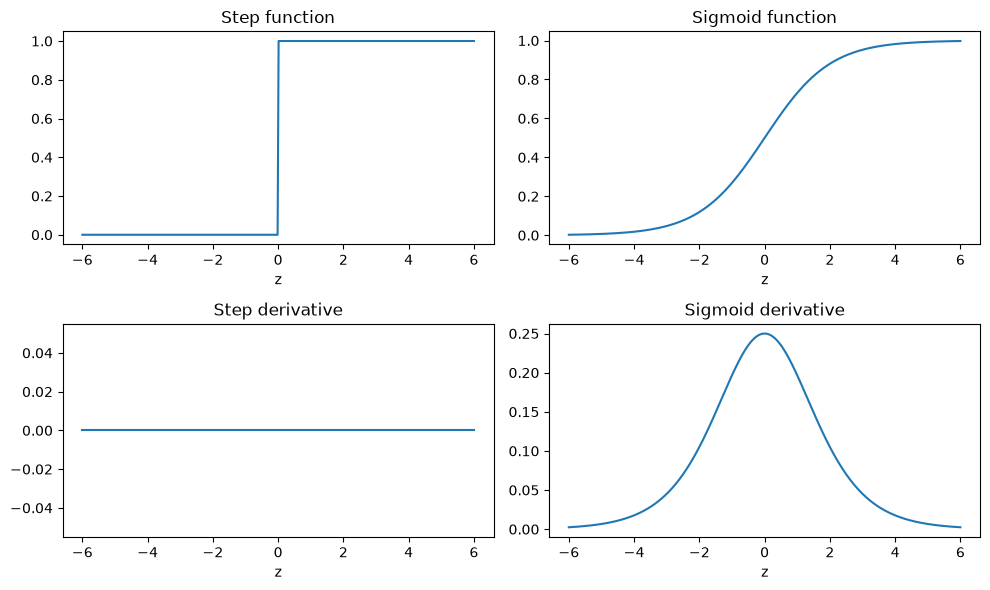

Max derivative of step: 0.0
Max derivative of sigmoid: 0.25


In [6]:
# Task 1.1

def step(z):
    return np.where(z >= 0, 1, 0)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def step_derivative(z):
    return np.zeros_like(z)

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

z = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

axes[0, 0].plot(z, step(z))
axes[0, 0].set_title("Step function")

axes[0, 1].plot(z, sigmoid(z))
axes[0, 1].set_title("Sigmoid function")

axes[1, 0].plot(z, step_derivative(z))
axes[1, 0].set_title("Step derivative")

axes[1, 1].plot(z, sigmoid_derivative(z))
axes[1, 1].set_title("Sigmoid derivative")

for ax in axes.flat:
    ax.set_xlabel("z")

plt.tight_layout()
plt.show()

print("Max derivative of step:", step_derivative(z).max())
print("Max derivative of sigmoid:", round(sigmoid_derivative(z).max(), 4))

**Interpretation:** The step function is flat, so its slope is 0 everywhere, and gradient descent has no signal to move the weights, so it cannot be trained. Sigmoid is smooth with a slope up to 0.25 at z = 0, so it gives gradient descent something to work with.

## Part 2 — Forward Pass: An MLP Solves XOR

### 2.1 Forward Pass Function
**Task 2.1** — Write `forward`. Use the step function with W1=[[1,1],[1,1]], b1=[−0.5,−1.5], W2=[[1],[−2]], b2=[−0.5]. Print the XOR table.

In [7]:
# Task 2.1

import pandas as pd

def forward(X, W1, b1, W2, b2, f):
    h = f(X @ W1 + b1)
    y_hat = f(h @ W2 + b2)
    return h, y_hat

W1 = np.array([[1, 1], [1, 1]])
b1 = np.array([-0.5, -1.5])
W2 = np.array([[1], [-2]])
b2 = np.array([-0.5])

h, y_hat = forward(X_xor, W1, b1, W2, b2, step)

xor_table = pd.DataFrame({
    "x1": X_xor[:, 0],
    "x2": X_xor[:, 1],
    "h1": h[:, 0],
    "h2": h[:, 1],
    "y_hat": y_hat[:, 0],
    "true y": y_xor
})

xor_table

,x1,x2,h1,h2,y_hat,true y
0,0,0,0,0,0,0
1,0,1,1,0,1,1
2,1,0,1,0,1,1
3,1,1,1,1,0,0


**Interpretation:** All 4 predictions match the true y, so this MLP solves XOR. h₁ is the OR gate  and h₂ is the AND gate. The output fires when OR is on and AND is off, which is exactly XOR.

## Part 3 — Gradient Descent and the Learning Rate

**Task 3.1** — Minimise L(w)=(w−3)² from w=−4 for 30 steps with η = 0.01, 0.1, 0.9, 1.05. Plot w vs step.

eta = 0.01 | final w = -0.8184 | final loss = 14.580104
eta = 0.1 | final w = 2.9913 | final loss = 7.5e-05
eta = 0.9 | final w = 2.9913 | final loss = 7.5e-05
eta = 1.05 | final w = -119.1458 | final loss = 14919.600338


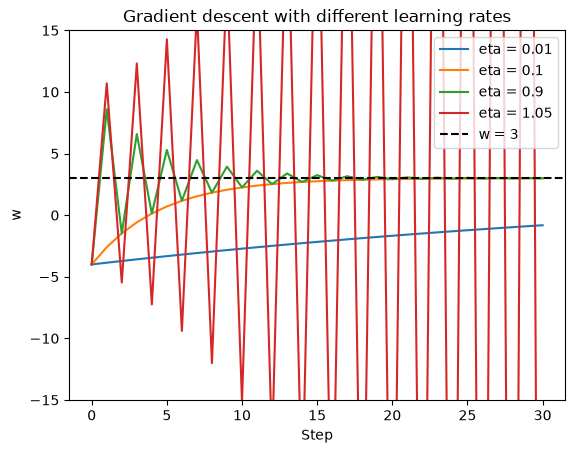

In [8]:
# Task 3.1

def gradient_descent(w0, eta, steps):
    w = w0
    values = [w]
    for i in range(steps):
        grad = 2 * (w - 3)
        w = w - eta * grad
        values.append(w)
    return values

for eta in [0.01, 0.1, 0.9, 1.05]:
    values = gradient_descent(-4, eta, 30)
    plt.plot(values, label="eta = " + str(eta))
    print("eta =", eta, "| final w =", round(values[-1], 4), "| final loss =", round((values[-1] - 3) ** 2, 6))

plt.axhline(3, color="black", linestyle="--", label="w = 3")
plt.ylim(-15, 15)
plt.xlabel("Step")
plt.ylabel("w")
plt.title("Gradient descent with different learning rates")
plt.legend()
plt.show()

**Interpretation:** η = 0.01 is too slow: after 30 steps w is still −0.82. η = 0.1 is good: it goes smoothly to w = 2.99. η = 0.9 zig-zags around 3 but still settles at 2.99. η = 1.05 blows up: every step overshoots by more than it fixes, so w ends at −119.15 and leaves the plot.

## Part 6 — Graded Questions
> Answer each question in a Markdown cell below using **your own numbers** from the lab.

**Q1 [4 marks]** — (a) Show W₂(W₁x + b₁) + b₂ = Wx + b and write W and b. (b) Why was the step function replaced by sigmoid for backpropagation?

**(a)** W₂(W₁x + b₁) + b₂ = W₂W₁x + W₂b₁ + b₂ = (W₂W₁)x + (W₂b₁ + b₂). So **W = W₂W₁** and **b = W₂b₁ + b₂**, which is just one linear layer, so stacking layers without an activation adds nothing. (With row inputs in code this is W = W1 @ W2 and b = b1 @ W2 + b2.)

**(b)** In my Task 1.1 plot the step function is flat, so its slope is 0 everywhere (max derivative 0.0). Backpropagation would get a zero gradient and no weight would ever change. Sigmoid is smooth with a slope up to 0.25, so it gives a useful gradient, which is why it replaced the step function.

**Q2 [4 marks]** — Forward pass by hand: W1=[[0.2,0.4],[0.6,−0.1]], b1=[0,0.1], W2=[[0.5],[−0.3]], b2=[0.2], x=[1,2], sigmoid everywhere. Compute h₁, h₂, ŷ (3 decimals) and check with your forward function.

In [9]:
# Q2

W1_q = np.array([[0.2, 0.4], [0.6, -0.1]])
b1_q = np.array([0, 0.1])
W2_q = np.array([[0.5], [-0.3]])
b2_q = np.array([0.2])
x_q = np.array([[1, 2]])

h_q, y_q = forward(x_q, W1_q, b1_q, W2_q, b2_q, sigmoid)

print("h1 =", round(h_q[0, 0], 3))
print("h2 =", round(h_q[0, 1], 3))
print("y_hat =", round(y_q[0, 0], 3))

h1 = 0.802
h2 = 0.574
y_hat = 0.606


By hand (sigmoid everywhere):

- z₁ = 1×0.2 + 2×0.6 + 0 = 1.4 and z₂ = 1×0.4 + 2×(−0.1) + 0.1 = 0.3
- h₁ = σ(1.4) = **0.802** and h₂ = σ(0.3) = **0.574**
- z = 0.5×0.802 + (−0.3)×0.574 + 0.2 = 0.429
- ŷ = σ(0.429) = **0.606**

My forward function printed the same values (h₁ = 0.802, h₂ = 0.574, ŷ = 0.606), so the hand calculation matches.